### **TIDIGITS**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from library.gmm import GMM
from library.knn import KNN
from library.lda import LDA
from library.pca import PCA
from library.svm import SVM

def show_clusters(X, y):
    X = X - X.mean(axis=0)

    _, _, V = np.linalg.svd(X, full_matrices=False)
    points = X @ V[:2].T

    for label in np.unique(y):
        mask = y == label
        plt.scatter(points[mask, 0], points[mask, 1], s=2, label=label)

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.show()

### **Load Data**

In [3]:
import os
sequences = []
labels = []
for digit in [2, 4, 7]:
    with np.load(f"./data/tidigits/{digit}.npz") as data:
        for key in data.files:
            sequences.append(data[key])
            labels.append(digit)

y = np.array(labels)

print("Recordings:", len(sequences))
print("Labels:", y.shape)

Recordings: 1350
Labels: (1350,)


### **Shuffle and Split**

In [4]:
rng = np.random.default_rng(42)
indices = rng.permutation(len(y))
train_end = int(0.6 * len(y))
val_end = int(0.8 * len(y))

train_indices = indices[:train_end]
val_indices = indices[train_end:val_end]
test_indices = indices[val_end:]

y_train = y[train_indices]
y_val = y[val_indices]
y_test = y[test_indices]

### **Sequence Length Distribution**

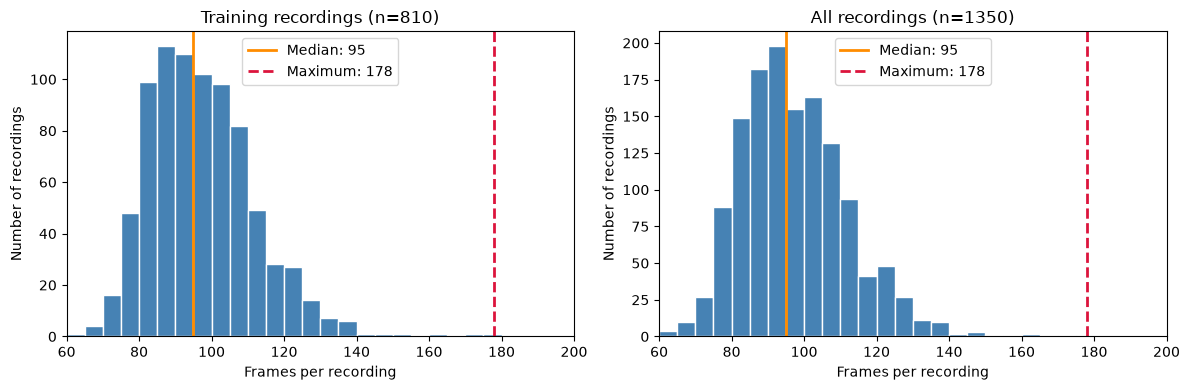

In [5]:
lengths = np.array([len(s) for s in sequences])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, values, title in zip(axes, [lengths[train_indices], lengths],
                            ["Training recordings", "All recordings"]):
    ax.hist(values, bins=np.arange(60, 201, 5), color="steelblue", edgecolor="white")
    ax.axvline(np.median(values), color="darkorange", linewidth=2,
               label=f"Median: {np.median(values):.0f}")
    ax.axvline(values.max(), color="crimson", linestyle="--", linewidth=2,
               label=f"Maximum: {values.max()}")
    ax.set_title(f"{title} (n={len(values)})")
    ax.set_xlabel("Frames per recording")
    ax.set_ylabel("Number of recordings")
    ax.set_xlim(60, 200)
    ax.legend()
plt.tight_layout()
plt.show()

### **Padding**

In [6]:
raw_train_sequences = [sequences[i] for i in train_indices]
raw_val_sequences = [sequences[i] for i in val_indices]
raw_test_sequences = [sequences[i] for i in test_indices]
frame_length = int(np.median([len(s) for s in raw_train_sequences]))

def pad_sequences(recordings):
    padded = []
    for recording in recordings:
        values = np.zeros((frame_length, recording.shape[1]))
        count = min(len(recording), frame_length)
        values[:count] = recording[:count]
        padded.append(values)
    return padded

train_sequences = pad_sequences(raw_train_sequences)
val_sequences = pad_sequences(raw_val_sequences)
test_sequences = pad_sequences(raw_test_sequences)
X_train = np.array(train_sequences).reshape(len(train_sequences), -1)
X_val = np.array(val_sequences).reshape(len(val_sequences), -1)
X_test = np.array(test_sequences).reshape(len(test_sequences), -1)
print("Target frames:", frame_length)

Target frames: 95


In [7]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Class order: [2 4 7]
Train: (810, 3705)
Validation: (270, 3705)
Test: (270, 3705)


### **Training Coordinates for GMM and LDA**

In [8]:
feature_mean = X_train.mean(axis=0)
_, _, vectors = np.linalg.svd(X_train - feature_mean, full_matrices=False)
basis = vectors.T
X_train_gaussian = (X_train - feature_mean) @ basis
X_val_gaussian = (X_val - feature_mean) @ basis
X_test_gaussian = (X_test - feature_mean) @ basis
print("All training directions retained:", X_train_gaussian.shape)

All training directions retained: (810, 810)


### **2D PCA Visualization**

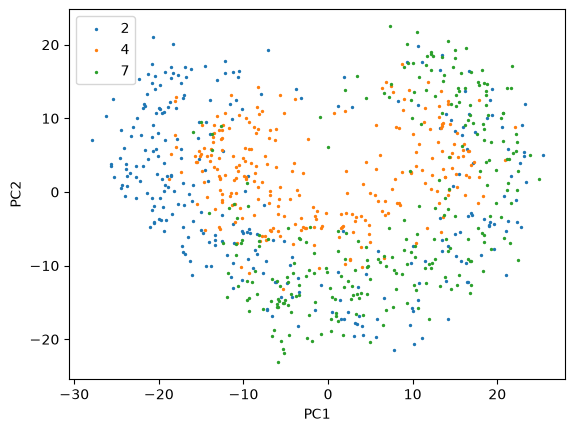

In [9]:
show_clusters(X_train_gaussian, y_train)

### **GMM**

In [12]:
models = []
priors = []
for label in classes:
    samples = X_train_gaussian[y_train == label]
    model = GMM(n_components=3, regularization=1e-3, iterations=100, convergence_tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train_gaussian))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.iterations:
        print("Iteration limit reached; convergence is not guaranteed.")

Class 2 EM iterations: 2
Class 4 EM iterations: 2
Class 7 EM iterations: 2


In [13]:
val_scores = np.column_stack([model.score_samples(X_val_gaussian) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test_gaussian) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]

In [14]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)

Validation accuracy: 0.9444444444444444
Test accuracy: 0.9444444444444444
Test confusion matrix:
 [[85  3  0]
 [ 4 88  2]
 [ 2  4 82]]


### **KNN**

In [16]:
knn = KNN(neighbors=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)

In [17]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)

Validation accuracy: 0.9629629629629629
Test accuracy: 0.9814814814814815
Test confusion matrix:
 [[88  0  0]
 [ 2 92  0]
 [ 3  0 85]]


### **LDA**

In [18]:
lda = LDA()
lda.fit(X_train_gaussian, y_train)
lda_val_predictions = lda.predict(X_val_gaussian)
lda_test_predictions = lda.predict(X_test_gaussian)

In [19]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)

Validation accuracy: 0.8481481481481481
Test accuracy: 0.8666666666666667
Test confusion matrix:
 [[77  4  7]
 [ 8 81  5]
 [ 8  4 76]]


### **SVM**

In [20]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)

One-vs-rest classifiers: 3
Gaussian sigma: 29.288777023875316
Converged: True
Largest KKT gap: 0.0009983085188846053


In [21]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)

Validation accuracy: 0.937037037037037
Test accuracy: 0.937037037037037
Test confusion matrix:
 [[78  0 10]
 [ 1 89  4]
 [ 2  0 86]]


### **PCA**

In [24]:
K = 39
pca = PCA(n_components=K)
pca.fit(X_train_gaussian)
X_train_pca = pca.transform(X_train_gaussian)
X_val_pca = pca.transform(X_val_gaussian)
X_test_pca = pca.transform(X_test_gaussian)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)

Train: (810, 39)
Validation: (270, 39)
Test: (270, 39)


### **GMM with PCA**

In [26]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(n_components=3, regularization=1e-3, iterations=100, convergence_tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.iterations:
        print("Iteration limit reached; convergence is not guaranteed.")

Class 2 EM iterations: 2
Class 4 EM iterations: 2
Class 7 EM iterations: 2


In [27]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]

In [28]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)

Validation accuracy: 0.937037037037037
Test accuracy: 0.937037037037037
Test confusion matrix:
 [[86  0  2]
 [11 80  3]
 [ 1  0 87]]


### **KNN with PCA**

In [30]:
knn_pca = KNN(neighbors=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)

In [31]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)

Validation accuracy: 0.9666666666666667
Test accuracy: 0.9814814814814815
Test confusion matrix:
 [[87  0  1]
 [ 2 91  1]
 [ 1  0 87]]


### **LDA with PCA**

In [32]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)

In [33]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)

Validation accuracy: 0.8407407407407408
Test accuracy: 0.8555555555555555
Test confusion matrix:
 [[76  3  9]
 [15 76  3]
 [ 4  5 79]]


### **SVM with PCA**

In [34]:
svm_pca = SVM()
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)

One-vs-rest classifiers: 3
Gaussian sigma: 19.533909934349822
Converged: True
Largest KKT gap: 0.0009993241411627718


In [35]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)

Validation accuracy: 0.9777777777777777
Test accuracy: 0.9814814814814815
Test confusion matrix:
 [[87  1  0]
 [ 1 92  1]
 [ 2  0 86]]


### **Accuracy Comparison**

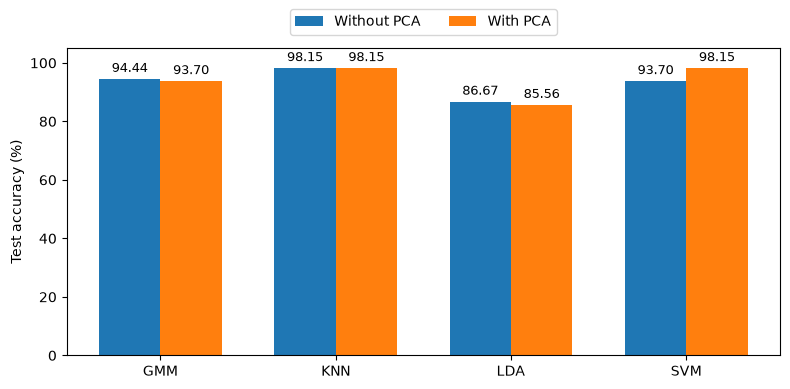

In [36]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()